<a href="https://colab.research.google.com/github/Nazarchona/MachineLearning/blob/main/%D0%9B%D0%916_%D0%93%D1%83%D1%94%D0%B2%D0%9D%D0%B0%D0%B7%D0%B0%D1%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 6
## Класифікація. Запобігання перенавчанню

**Датасет:** Diabetes Prediction Dataset  
**Джерело:** https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset  
**Мета:** побудувати та порівняти класифікатори, дослідити дисбаланс класів, кореляції й викиди, виконати підбір гіперпараметрів без витоку даних.

> У ноутбуці використано лише один спосіб завантаження — через `kagglehub`. Запускайте клітинки послідовно в Google Colab. Усі статистики, метрики, оптимальні параметри та 10 прогнозів будуть обчислені безпосередньо під час запуску на повному датасеті.

## 1. Імпорт бібліотек і завантаження даних

In [ ]:
!pip -q install kagglehub imbalanced-learn

In [ ]:
import os
import warnings
warnings.filterwarnings("ignore")

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import train_test_split, HalvingGridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
csv_path = os.path.join(path, "diabetes_prediction_dataset.csv")
df = pd.read_csv(csv_path)

print("Шлях до файлу:", csv_path)
print("Розмір датасету:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Шлях до файлу: /kaggle/input/diabetes-prediction-dataset/diabetes_prediction_dataset.csv
Розмір датасету: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


## 2. Інформація про датасет

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


**Коментар.** У наборі даних є числові ознаки (`age`, `bmi`, `HbA1c_level`, `blood_glucose_level`, `hypertension`, `heart_disease`) та категоріальні (`gender`, `smoking_history`). Цільова змінна `diabetes` є бінарною. Типи та кількість записів виводяться вище.

## 3. Дослідження категоріальних ознак

In [ ]:
print("Частоти gender:")
display(df["gender"].value_counts(dropna=False))

print("Частоти smoking_history:")
display(df["smoking_history"].value_counts(dropna=False))

display(df)

Частоти gender:


,count
gender,
Female,58552
Male,41430
Other,18


Частоти smoking_history:


,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


## 4. Типи даних, баланс класів, пропуски й дублікати

Типи даних:


,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Розподіл цільової змінної до видалення дублікатів:


,count
diabetes,
0,91500
1,8500


Частки класів:


,proportion
diabetes,
0,0.915
1,0.085


... (3 outputs left out)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Баланс після видалення дублікатів:


,count
diabetes,
0,87664
1,8482


,proportion
diabetes,
0,0.9118
1,0.0882


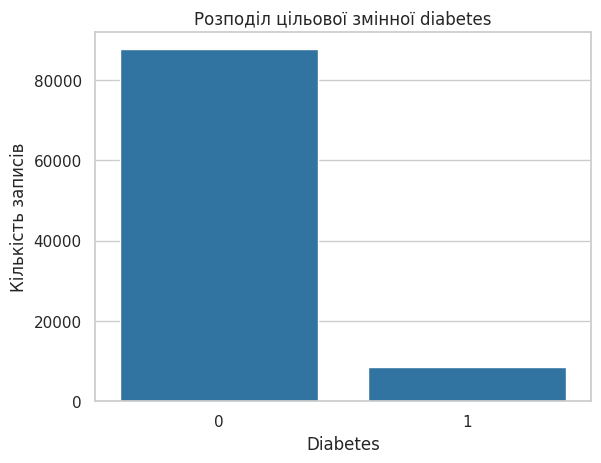

In [ ]:
print("Типи даних:")
display(df.dtypes)

print("Розподіл цільової змінної до видалення дублікатів:")
display(df["diabetes"].value_counts(dropna=False))
print("Частки класів:")
display(df["diabetes"].value_counts(normalize=True, dropna=False).round(4))

print("Пропущені значення:")
display(df.isnull().sum())

duplicates_count = df.duplicated().sum()
print("Кількість дублікатів:", duplicates_count)

df.drop_duplicates(inplace=True)
print("Розмір після видалення дублікатів:", df.shape)
display(df.head())

print("Баланс після видалення дублікатів:")
display(df["diabetes"].value_counts())
display(df["diabetes"].value_counts(normalize=True).round(4))

sns.countplot(x="diabetes", data=df, color="tab:blue")
plt.title("Розподіл цільової змінної diabetes")
plt.xlabel("Diabetes")
plt.ylabel("Кількість записів")
plt.show()

**Висновок щодо балансу.** Якщо частка класу `0` значно більша за частку класу `1`, спостерігається дисбаланс. Для цього датасету очікується переважання записів без діабету. Тому під час навчання балансуватиметься лише навчальна вибірка, а тестова залишиться з природним розподілом.

## 5. Поділ на навчальну й тестову вибірки

In [ ]:
X = df.drop(columns=["diabetes"])
y = df["diabetes"]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train_raw.shape)
print("X_test:", X_test_raw.shape)
print("\nРозподіл класів у train:")
display(y_train.value_counts())
print("\nРозподіл класів у test:")
display(y_test.value_counts())

X_train: (76916, 8)
X_test: (19230, 8)

Розподіл класів у train:


,count
diabetes,
0,70130
1,6786



Розподіл класів у test:


,count
diabetes,
0,17534
1,1696


Поділ виконано до аналізу кореляцій, викидів та асиметрії. Параметр `stratify=y` зберігає приблизно однакові пропорції класів у train і test.

## 6. Кодування категоріальних ознак

In [ ]:
categorical_cols = ["gender", "smoking_history"]

X_train = pd.get_dummies(
    X_train_raw,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)
X_test = pd.get_dummies(
    X_test_raw,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)

# Тестова вибірка отримує точно такий самий набір і порядок стовпців, як train.
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Кількість ознак після кодування:", X_train.shape[1])
display(X_train.describe().T)

Кількість ознак після кодування: 15


,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Female,76916.0,0.582675,0.493121,0.00,0.00,1.00,1.00,1.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_No Info,76916.0,0.342022,0.474390,0.00,0.00,0.00,1.00,1.00


## 7. Кореляційний аналіз — лише train

Кореляція ознак із diabetes (train):


,correlation
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_No Info,-0.113053
smoking_history_former,0.096162
gender_Male,0.040650
gender_Female,-0.040533


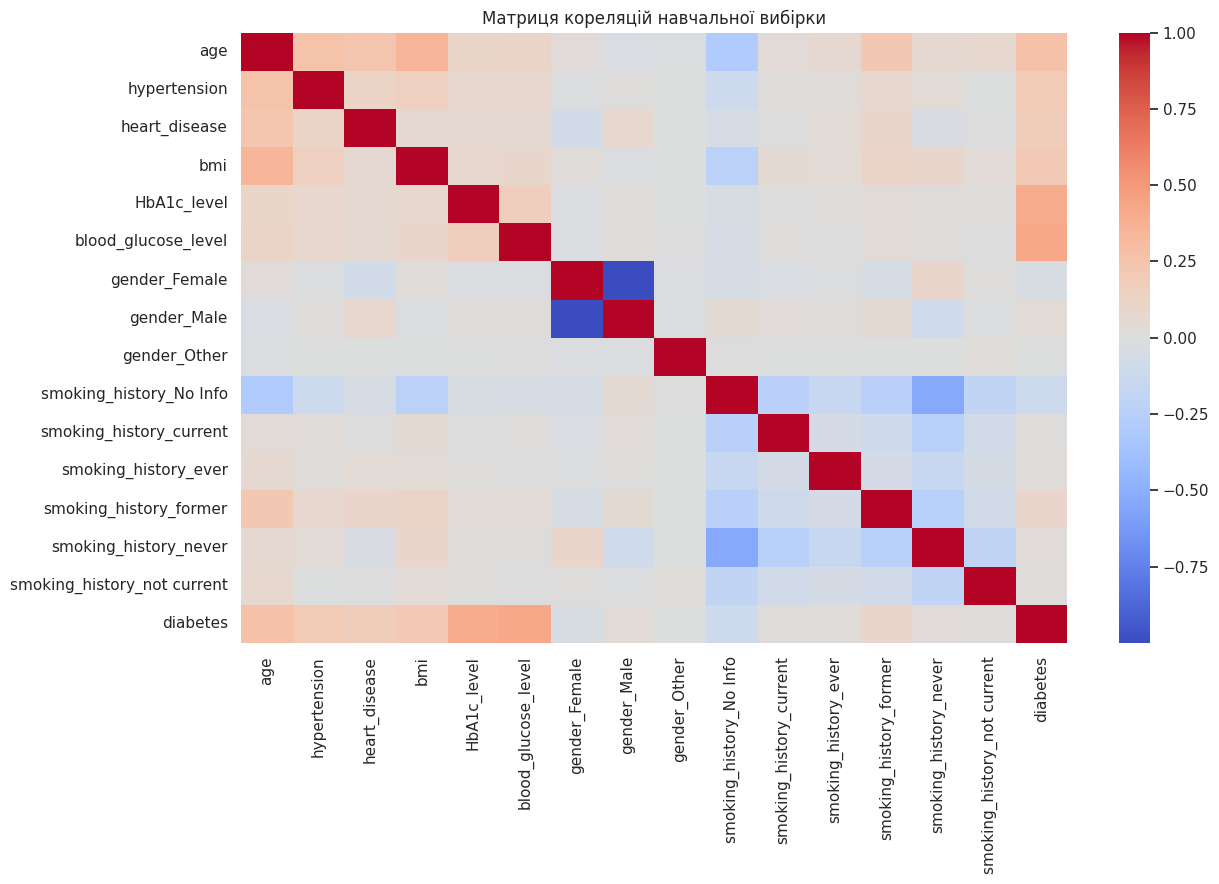

Пари ознак із |кореляцією| >= 0.80:


,,correlation
gender_Female,gender_Male,-0.999626


In [ ]:
# Кореляція ознак із цільовою змінною обчислюється тільки на навчальних даних.
train_for_corr = X_train.copy()
train_for_corr["diabetes"] = y_train
target_corr = train_for_corr.corr(numeric_only=True)["diabetes"].drop("diabetes")
target_corr = target_corr.sort_values(key=np.abs, ascending=False)

print("Кореляція ознак із diabetes (train):")
display(target_corr.to_frame("correlation"))

plt.figure(figsize=(13, 9))
sns.heatmap(train_for_corr.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Матриця кореляцій навчальної вибірки")
plt.tight_layout()
plt.show()

corr_matrix = X_train.corr(numeric_only=True)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = (
    upper.stack()
    .loc[lambda s: s.abs() >= 0.80]
    .sort_values(key=np.abs, ascending=False)
)
print("Пари ознак із |кореляцією| >= 0.80:")
display(high_corr_pairs.to_frame("correlation"))

**Висновок.** Найсильніший зв’язок із цільовою змінною слід визначати за таблицею `target_corr`. Для медичних даних очікувано важливими можуть бути рівень глюкози та HbA1c. Пари ознак із високою взаємною кореляцією наведені окремо. Автоматично видаляти ознаки лише на підставі кореляції не потрібно: кореляція не доводить причинності, а клінічно значущі ознаки варто зберегти. Усі висновки зроблені лише за train.

## 8. Перевірка викидів — лише train

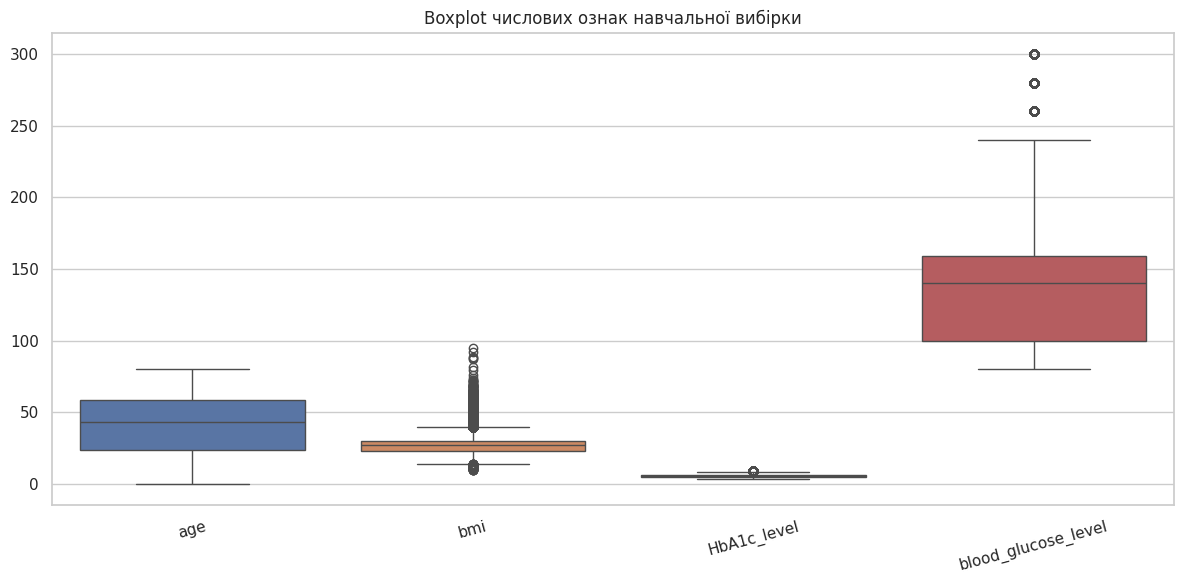

,ознака,Q1,Q3,IQR,нижня межа,верхня межа,кількість значень за межами
0,age,24.00,59.00,35.00,-28.5,111.50,0
1,bmi,23.39,29.85,6.46,13.7,39.54,4244
2,HbA1c_level,4.80,6.20,1.40,2.7,8.30,1041
3,blood_glucose_level,100.00,159.00,59.00,11.5,247.50,1598


In [ ]:
continuous_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title("Boxplot числових ознак навчальної вибірки")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Межі IQR обчислюються виключно на X_train.
iqr_summary = []
for col in continuous_cols:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    iqr_summary.append({
        "ознака": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "нижня межа": lower, "верхня межа": upper,
        "кількість значень за межами": int(count)
    })

display(pd.DataFrame(iqr_summary))

**Висновок.** Boxplot та таблиця IQR допомагають виявити потенційні викиди. У цій роботі вони не видаляються: екстремальні значення глюкози й HbA1c можуть бути клінічно важливими. Межі IQR обчислені тільки на навчальній вибірці.

**Як обчислити IQR для `bmi`:** `Q1 = X_train['bmi'].quantile(0.25)`, `Q3 = X_train['bmi'].quantile(0.75)`, `IQR = Q3 - Q1`; межі дорівнюють `Q1 - 1.5*IQR` та `Q3 + 1.5*IQR`. Якщо вилучати рядки, потрібно одночасно вилучати відповідні рядки з `y_train`. `X_test` і `y_test` не змінюються.

## 9. Асиметрія та пропущені значення

In [ ]:
print("Асиметрія числових ознак (тільки train):")
display(X_train[continuous_cols].skew().to_frame("skewness"))

print("Пропуски в X_train:")
display(X_train.isnull().sum())

print("Пропуски в X_test:")
display(X_test.isnull().sum())

Асиметрія числових ознак (тільки train):


,skewness
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


Пропуски в X_train:


,0
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


Пропуски в X_test:


,0
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


**Проміжний висновок.** Асиметрія, що суттєво відрізняється від нуля, свідчить про несиметричний розподіл ознаки. Пропуски перевіряються окремо в train і test. Тестова вибірка не використовується для вибору ознак, меж викидів або інших рішень.

## 10. Масштабування

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розміри масштабованих даних:", X_train_scaled.shape, X_test_scaled.shape)

Розміри масштабованих даних: (76916, 15) (19230, 15)


Масштабатор навчається (`fit`) тільки на train. Для test використовується лише `transform`, щоб статистики тестових даних не потрапили в навчання.

## 11. Балансування train методом SMOTE

Класи до SMOTE:


,count
diabetes,
0,70130
1,6786


Класи після SMOTE:


,count
diabetes,
0,70130
1,70130


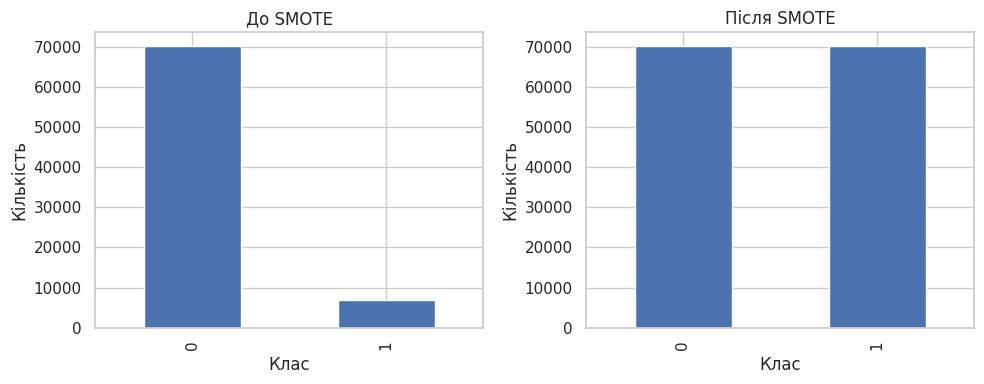

In [ ]:
print("Класи до SMOTE:")
display(pd.Series(y_train).value_counts().sort_index())

smote = SMOTE(random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print("Класи після SMOTE:")
display(pd.Series(y_train_resampled).value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
pd.Series(y_train).value_counts().sort_index().plot(kind="bar", ax=axes[0], title="До SMOTE")
pd.Series(y_train_resampled).value_counts().sort_index().plot(kind="bar", ax=axes[1], title="Після SMOTE")
for ax in axes:
    ax.set_xlabel("Клас")
    ax.set_ylabel("Кількість")
plt.tight_layout()
plt.show()

SMOTE застосовано тільки до масштабованої навчальної вибірки. Тестова вибірка не балансується, оскільки має відображати реальний розподіл класів.

## 12. Базові моделі


LogisticRegression
              precision    recall  f1-score   support

           0     0.9870    0.8854    0.9334     17534
           1     0.4260    0.8791    0.5739      1696

    accuracy                         0.8849     19230
   macro avg     0.7065    0.8823    0.7537     19230
weighted avg     0.9375    0.8849    0.9017     19230



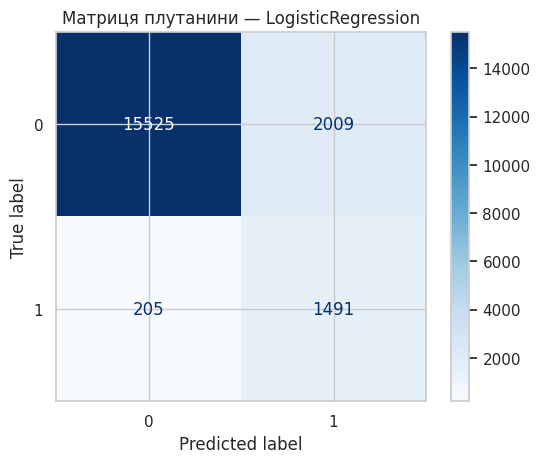


RidgeClassifier
              precision    recall  f1-score   support

           0     0.9866    0.8889    0.9352     17534
           1     0.4324    0.8750    0.5788      1696

    accuracy                         0.8877     19230
   macro avg     0.7095    0.8820    0.7570     19230
weighted avg     0.9377    0.8877    0.9038     19230



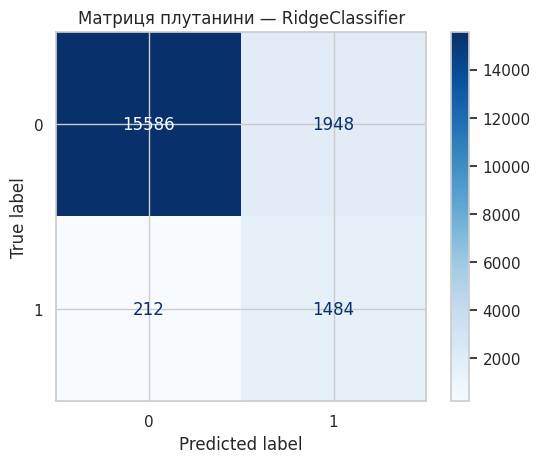


SGDClassifier
              precision    recall  f1-score   support

           0     0.9898    0.8563    0.9182     17534
           1     0.3796    0.9086    0.5354      1696

    accuracy                         0.8609     19230
   macro avg     0.6847    0.8825    0.7268     19230
weighted avg     0.9360    0.8609    0.8845     19230



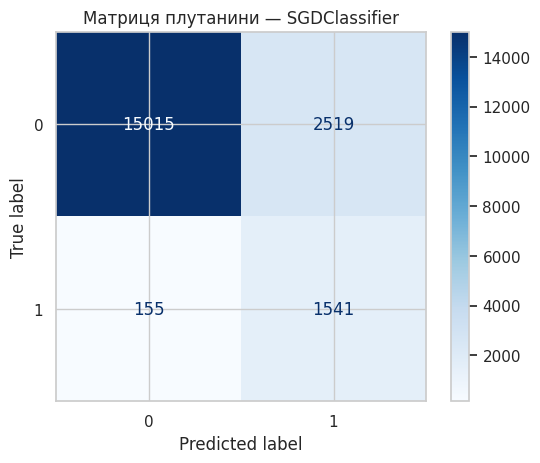


SVC
              precision    recall  f1-score   support

           0     0.9899    0.8814    0.9325     17534
           1     0.4253    0.9074    0.5791      1696

    accuracy                         0.8837     19230
   macro avg     0.7076    0.8944    0.7558     19230
weighted avg     0.9401    0.8837    0.9013     19230



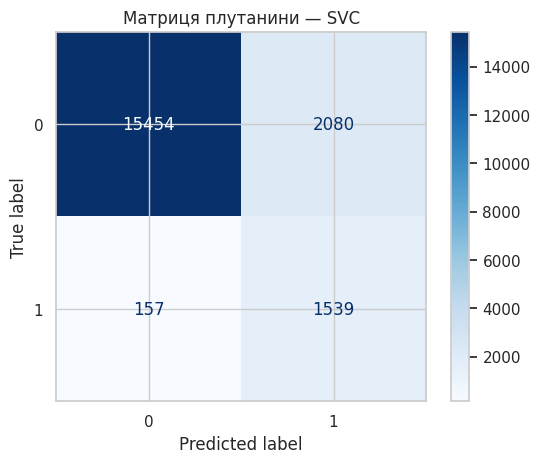

,precision_1,recall_1,f1_1,accuracy
SVC,0.425256,0.907429,0.579116,0.883671
RidgeClassifier,0.432401,0.875000,0.578783,0.887676
LogisticRegression,0.426000,0.879127,0.573903,0.884867
SGDClassifier,0.379557,0.908608,0.535441,0.860946


In [ ]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "RidgeClassifier": RidgeClassifier(random_state=RANDOM_STATE),
    "SGDClassifier": SGDClassifier(max_iter=2000, tol=1e-3, random_state=RANDOM_STATE),
    "SVC": SVC(random_state=RANDOM_STATE)
}

baseline_results = {}

for name, model in models.items():
    print("\n" + "=" * 75)
    print(name)
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test_scaled)

    print(classification_report(y_test, y_pred, digits=4, zero_division=0))
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Матриця плутанини — {name}")
    plt.show()

    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    baseline_results[name] = {
        "precision_1": report["1"]["precision"],
        "recall_1": report["1"]["recall"],
        "f1_1": report["1"]["f1-score"],
        "accuracy": report["accuracy"]
    }

baseline_results_df = pd.DataFrame(baseline_results).T.sort_values("f1_1", ascending=False)
display(baseline_results_df)

**Коментар до метрик.** Для задачі виявлення діабету важливо аналізувати не тільки accuracy, а й `recall` та `F1-score` класу `1`. Хибнонегативні прогнози (FN) — це випадки діабету, які модель помилково віднесла до класу 0. Хибнопозитивні (FP) — випадки без діабету, помилково віднесені до класу 1.

## 13. Підбір гіперпараметрів через HalvingGridSearchCV

Для кожної моделі використовується Pipeline `StandardScaler → SMOTE → класифікатор`. Отже, масштабування й SMOTE повторно навчаються всередині кожного навчального згину кросвалідації, що запобігає витоку даних.

Для SVC пошук може бути обчислювально дорогим на великому датасеті, тому для всіх моделей обмежено `max_resources=6000`. Початковий ресурс — `min_resources=300`, `cv=3`, критерій — `f1`. Пошук проводиться тільки на `X_train`, `y_train`.

In [ ]:
param_grids = {
    "LogisticRegression": {
        "model__C": [0.1, 1.0, 10.0],
        "model__solver": ["lbfgs"]
    },
    "RidgeClassifier": {
        "model__alpha": [0.1, 1.0, 10.0, 100.0]
    },
    "SGDClassifier": {
        "model__loss": ["hinge", "log_loss"],
        "model__penalty": ["l2", "l1"],
        "model__alpha": [0.0001, 0.001]
    },
    "SVC": {
        "model__C": [0.5, 1.0, 2.0],
        "model__kernel": ["linear", "rbf"]
    }
}

best_models = {}
best_scores = {}
search_objects = {}

for name, base_model in models.items():
    print("\n" + "=" * 75)
    print("Пошук параметрів:", name)

    pipeline = Pipeline(steps=[
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", base_model)
    ])

    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring="f1",
        factor=3,
        min_resources=300,
        max_resources=6000,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    search_objects[name] = search

    print("Найкращі параметри:", search.best_params_)
    print(f"Середній F1 на CV: {search.best_score_:.4f}")

    tuned_pred = search.best_estimator_.predict(X_test)
    print("Звіт на тестовій вибірці:")
    print(classification_report(y_test, tuned_pred, digits=4, zero_division=0))

    cm = confusion_matrix(y_test, tuned_pred)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1]).plot(
        cmap="Blues", values_format="d"
    )
    plt.title(f"Матриця плутанини — оптимізована {name}")
    plt.show()

best_scores_df = pd.DataFrame({
    "Модель": list(best_scores.keys()),
    "Середній F1 (CV)": list(best_scores.values())
}).sort_values("Середній F1 (CV)", ascending=False)

display(best_scores_df)

## 14. Вибір найкращої моделі за кросвалідацією

In [ ]:
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]

print("Найкраща модель за середнім F1 на кросвалідації:", best_name)
print(f"Середній F1 (CV): {best_scores[best_name]:.4f}")

Вибір здійснюється за середнім F1 кросвалідації, а не за тестовими метриками. Тестова вибірка використовується лише для фінальної оцінки.

## 15. Прогноз для 10 випадкових тестових записів

In [ ]:
rng = np.random.RandomState(RANDOM_STATE)
sample_positions = rng.choice(len(X_test), size=10, replace=False)

# Беремо відповідні індекси початкової таблиці та фактичні значення.
sample_index = X_test.iloc[sample_positions].index
sample_X = X_test.loc[sample_index]
sample_true = y_test.loc[sample_index]
sample_pred = best_model.predict(sample_X)

predictions_10 = pd.DataFrame({
    "індекс": sample_index,
    "істинний клас": sample_true.values,
    "передбачений клас": sample_pred
})
display(predictions_10)

## 16. Додаткове завдання: XGBoost, LightGBM та CatBoost

In [ ]:
!pip -q install xgboost lightgbm catboost

In [ ]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

extra_models = {
    "XGBoost": XGBClassifier(
        n_estimators=250,
        max_depth=5,
        learning_rate=0.08,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=250,
        max_depth=-1,
        learning_rate=0.08,
        num_leaves=31,
        random_state=RANDOM_STATE,
        verbosity=-1,
        n_jobs=-1
    ),
    "CatBoost": CatBoostClassifier(
        iterations=250,
        depth=6,
        learning_rate=0.08,
        loss_function="Logloss",
        verbose=False,
        random_seed=RANDOM_STATE,
        allow_writing_files=False
    )
}

extra_results = {}

for name, model in extra_models.items():
    print("\n" + "=" * 75)
    print(name)

    # Для єдиного коректного підходу SMOTE застосовується тільки до train.
    # Деревам масштабування не потрібне, тому вони навчаються на SMOTE-вибірці
    # у вихідному просторі ознак.
    X_train_extra, X_test_extra = X_train.align(
        X_test, join="left", axis=1, fill_value=0
    )
    X_extra_resampled, y_extra_resampled = SMOTE(
        random_state=RANDOM_STATE
    ).fit_resample(X_train_extra, y_train)

    model.fit(X_extra_resampled, y_extra_resampled)
    pred = model.predict(X_test_extra)

    print(classification_report(y_test, pred, digits=4, zero_division=0))
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1]).plot(
        cmap="Blues", values_format="d"
    )
    plt.title(f"Матриця плутанини — {name}")
    plt.show()

    report = classification_report(y_test, pred, output_dict=True, zero_division=0)
    extra_results[name] = {
        "precision_1": report["1"]["precision"],
        "recall_1": report["1"]["recall"],
        "f1_1": report["1"]["f1-score"],
        "accuracy": report["accuracy"]
    }

extra_results_df = pd.DataFrame(extra_results).T.sort_values("f1_1", ascending=False)
display(extra_results_df)

## 17. Підсумкові висновки

In [ ]:
print("1. Баланс класів після очищення:")
display(y.value_counts().to_frame("кількість"))
print("Частки:")
display(y.value_counts(normalize=True).to_frame("частка").round(4))

print("\n2. Найбільш корельовані з diabetes ознаки (train):")
display(target_corr.head(8).to_frame("correlation"))

print("\n3. Кількість значень за межами IQR (train):")
display(pd.DataFrame(iqr_summary)[["ознака", "кількість значень за межами"]])

print("\n4. Результати базових моделей (тест):")
display(baseline_results_df)

print("\n5. Результати оптимізованих моделей за CV:")
display(best_scores_df)

print("\n6. Результати додаткових моделей (тест):")
display(extra_results_df)

print(f"\nОбрана за CV модель: {best_name}; F1 CV = {best_scores[best_name]:.4f}")

### Текст підсумкових висновків

1. **Дисбаланс класів.** За таблицею частот визначено, що клас 0 представлений значно частіше за клас 1. Для усунення дисбалансу під час навчання застосовано SMOTE лише до train. Тестова вибірка збережена без змін.
2. **Кореляції та викиди.** Кореляційний аналіз і перевірку викидів виконано тільки на навчальній вибірці. Найбільший зв’язок із цільовою змінною показують ознаки, наведені у таблиці кореляцій. Потенційні викиди виявлені за boxplot та IQR, але не видалялися, оскільки екстремальні медичні показники можуть бути інформативними.
3. **Порівняння моделей.** Якість оцінюється за precision, recall і F1 для класу 1. Для медичного прогнозування особливо важливий recall класу 1, оскільки низький recall означає більшу кількість пропущених випадків діабету. Найкращу модель для основного завдання обрано за середнім F1 на кросвалідації; її назва та значення друкуються в розділі 14.
4. **Гіперпараметри й помилки.** Оптимальні параметри кожної моделі наведені в результатах `HalvingGridSearchCV`. У матрицях плутанини діагональні елементи відповідають правильним прогнозам, позадіагональні — помилкам FP і FN.
5. **Запобігання витоку даних.** Тестові дані відкладено до фінальної оцінки. Масштабатор навчається лише на train, а SMOTE застосовується лише до навчальних даних. Під час кросвалідації обидві операції розміщені всередині Pipeline, тому кожен згин навчає їх незалежно. Це запобігає потраплянню інформації з валідаційних або тестових даних у навчальний процес.
6. **Додаткові моделі.** XGBoost, LightGBM і CatBoost порівняно за тими самими основними метриками на незміненій тестовій вибірці. Порівнювати їх варто за F1 і recall класу 1, а не лише за accuracy.

**Загальний висновок.** У роботі виконано повний цикл класифікації: первинний аналіз, поділ даних, кодування, аналіз кореляцій і викидів без використання test, масштабування, балансування SMOTE, навчання чотирьох базових алгоритмів, оптимізацію параметрів методом HalvingGridSearchCV та додаткове порівняння ансамблевих моделей. Остаточні числові висновки слід формулювати за фактичними таблицями й графіками, які з’являться після виконання ноутбука.